In [ ]:
import pandas as pd 
import numpy as np 
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import seaborn as sns 
from datasets.Harmonized_Datasets import harmonize


In [65]:
mf_ad = harmonize()['Moffitt']

/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


DeCampos Annotated data found!
Number of Harmonized Genes: 18672


In [ ]:
expr_df = mf_ad.to_df()
auc = mf_ad.obs['ABT-199']
gupta_geneset = ['VPREB3', 'CCR7', 'SORL1', 'TRABD2A', 'EFEMP1', 'TDO2']
results = {}
network = []
for gene in gupta_geneset:
    results[gene] = {'gene': [],'pval': [], 'r': []}
    for col in expr_df.columns:

        corr_result = spearmanr(expr_df[col], expr_df[gene])
        #if corr_result.pvalue < 0.05:
        results[gene]['gene'].append(col)
        results[gene]['pval'].append(corr_result.pvalue)
        results[gene]['r'].append(corr_result.statistic)

        if corr_result.pvalue < 0.05 and abs(corr_result.statistic) >= 0.7:
            if gene != col:
                network.append(col)

    results[gene] = pd.DataFrame(results[gene])

        

/tmp/ipykernel_63376/2273359153.py:10: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr_result = spearmanr(expr_df[col], expr_df[gene])


In [67]:
sample = results['VPREB3'].sort_values(by='r', ascending=False)


In [68]:
sample

,gene,pval,r
13399,VPREB3,0.000000e+00,1.000000
6114,PAX5,1.870726e-15,0.664379
12662,DTX1,2.617099e-15,0.661805
2229,RASAL1,5.678204e-15,0.655770
7313,AEBP1,5.635820e-12,0.595150
...,...,...,...
18292,BSPH1,NaN,NaN
18295,CT47A1,NaN,NaN
18599,TAF11L13,NaN,NaN
18613,FGF4,NaN,NaN


In [69]:
correlations = {}
for gene in gupta_geneset:
    df = results[gene]
    r = df['r']
    correlations[gene] = r 
    print(r)
#correlations
correlation_df = pd.DataFrame(correlations)

0       -0.057588
1        0.068443
2        0.057025
3       -0.053525
4       -0.055463
           ...   
18667   -0.228229
18668   -0.130675
18669   -0.193536
18670    0.429888
18671    0.273740
Name: r, Length: 18672, dtype: float64
0        0.045363
1       -0.022346
2        0.008873
3        0.100467
4        0.119964
           ...   
18667   -0.171958
18668   -0.010416
18669   -0.115473
18670    0.370284
18671    0.205299
Name: r, Length: 18672, dtype: float64
0        0.065353
1       -0.081832
2       -0.075309
3        0.045760
4        0.084900
           ...   
18667   -0.141736
18668   -0.076191
18669   -0.113958
18670    0.605142
18671    0.232810
Name: r, Length: 18672, dtype: float64
0        0.073508
1       -0.058027
2       -0.045126
3        0.033991
4        0.022888
           ...   
18667   -0.054059
18668    0.081940
18669    0.165205
18670   -0.076961
18671    0.050528
Name: r, Length: 18672, dtype: float64
0       -0.058639
1       -0.065466
2       -0.18145

In [70]:
correlation_df.index = expr_df.columns
correlation_df

,VPREB3,CCR7,SORL1,TRABD2A,EFEMP1,TDO2
ROS1,-0.057588,0.045363,0.065353,0.073508,-0.058639,0.053982
MS4A10,0.068443,-0.022346,-0.081832,-0.058027,-0.065466,0.014883
MCCD1,0.057025,0.008873,-0.075309,-0.045126,-0.181451,-0.109918
HSPB9,-0.053525,0.100467,0.045760,0.033991,0.014915,0.028641
CYB5D2,-0.055463,0.119964,0.084900,0.022888,0.010451,-0.177819
...,...,...,...,...,...,...
MAPDA,-0.228229,-0.171958,-0.141736,-0.054059,-0.018701,0.236430
GALNT16,-0.130675,-0.010416,-0.076191,0.081940,0.178183,0.140006
GOLGA4,-0.193536,-0.115473,-0.113958,0.165205,0.046956,0.145170
CLC,0.429888,0.370284,0.605142,-0.076961,-0.064424,-0.073240


<Axes: >

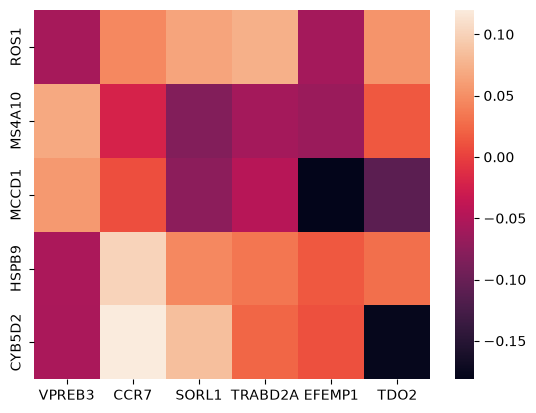

In [71]:
sns.heatmap(correlation_df.head())

In [78]:
len(set(network)) # this is just p value < 0.05

164

In [83]:
network

['VNN2',
 'GAS7',
 'ITGAM',
 'TREM1',
 'PRAM1',
 'CLEC4E',
 'ZNF385A',
 'SLC2A3',
 'ARAP3',
 'SERPINA1',
 'CD68',
 'GNA15',
 'KCNE3',
 'CSTA',
 'LILRB2',
 'F13A1',
 'IPCEF1',
 'MS4A6A',
 'SCIMP',
 'IGSF6',
 'MYO1F',
 'FPR2',
 'LILRA5',
 'CYP1B1',
 'PTGER4',
 'FCN1',
 'ASGR1',
 'ZEB2',
 'SIGLEC10',
 'NKG7',
 'TLR2',
 'CSF3R',
 'CD82',
 'ETS2',
 'IRF8',
 'FPR1',
 'IRAK3',
 'CD300LF',
 'EMILIN2',
 'SLC11A1',
 'KLK3',
 'PIK3CD',
 'TNFSF13',
 'LST1',
 'ADGRE2',
 'ARHGAP24',
 'C1orf162',
 'SIRPA',
 'LYZ',
 'PLXDC2',
 'ZNF467',
 'HLA-DRA',
 'FLVCR2',
 'HLA-DMB',
 'HHEX',
 'PIK3R5',
 'RASGRP2',
 'THBD',
 'GAPT',
 'DOCK5',
 'GASK1B',
 'FGR',
 'AQP9',
 'TYROBP',
 'LGALS2',
 'CLEC12A',
 'HK3',
 'TLR4',
 'NFAM1',
 'CD14',
 'ATP8B4',
 'APOBR',
 'LILRA6',
 'PGAP1',
 'CD244',
 'COTL1',
 'CD52',
 'RNASE2',
 'FYB1',
 'LILRA2',
 'CTBP2',
 'CD300E',
 'ITGAX',
 'KMT2A',
 'TTC39C',
 'S100A8',
 'SIGLEC9',
 'C3AR1',
 'MEFV',
 'MPEG1',
 'TSHZ3',
 'ZNF703',
 'SLC24A4',
 'ANK1',
 'C19orf38',
 'OSCAR',
 'TNFRSF1